In [1]:
%load_ext autoreload
%autoreload 2

Only the GFA dataset contains a land cover attribute. This notebook 1) processes the MODIS data into GeoTiff files, 2) evaluates how well the MODIS Land Cover product can be used to predict the given categories in the USA, and 3) use the MODIS product to assign land cover categories to fires in other datasets.

### Convert MODIS data into GeoTIFF files

In [3]:
import pandas as pd

from wildfire_stats import config as cfg
from wildfire_stats.data import classification as dcls
from wildfire_stats.data import io as dio
from wildfire_stats.data import rasters as drast
from wildfire_stats.plotting import landcover as plc
from wildfire_stats.reporting import tables as rtab

P = cfg.load_paths()
MIN_FIRE_SIZE = 6.45  # km²; minimum fire size. Set to 4 to reproduce the earlier analysis
cfg.set_overrides(min_fire=MIN_FIRE_SIZE)  # every library default (xmin, amin_min, ...) follows this
A = cfg.load_assumptions()  # A["min_fire"] == MIN_FIRE_SIZE
MF_TAG = dio.minfire_tag()  # filename tag, e.g. "minfire6p45"

In [4]:
# Convert all MODIS HDFs (downloaded from EarthData into P.modis) to LC_Type1 GeoTIFFs
tif_folder = P.modis / "GeoTIFF"
drast.convert_modis_hdf_to_tif(P.modis, tif_folder)

### Use MODIS GeoTIFFs to predict land cover type for each GFA fire in USA (2003-2016) and compare them to given GFA land cover attribute. This predicts the land cover type by finding all MODIS landcover types inside each fire's boundary, then the most common one spatially is defined as that fire's predicted land cover type.

In [5]:
y0, y1 = A["modis_years"]
gfa_global = dio.load_gfa(P.gfa, years=(y0, y1), bbox=dio.CONUS_BBOX, to_equal_area=False, verbose=False)
print(f"Number of GFA fires in USA ({y0}-{y1}): {len(gfa_global)}")

modis_by_year = drast.index_modis_by_year(tif_folder)
results_df = dcls.build_gfa_modis_validation(gfa_global, modis_by_year)

/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/.env/lib/python3.10/site-packages/pyogrio/raw.py:198: RuntimeWarning: /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2010.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/.env/lib/python3.10/site-packages/pyogrio/raw.py:198: RuntimeWarning: /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2016.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


Number of GFA fires in USA (2003-2016): 154917


/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/src/wildfire_stats/data/classification.py:190: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  results_df["area_km2"] = results_df.geometry.area / 1e6


In [6]:
# MIN_FIRE_SIZE is set in the setup cell (6.45 km² baseline; 4 km² = previous iteration)
gfa_classified = results_df[results_df["area_km2"] >= MIN_FIRE_SIZE].copy()

print(f"Fires >= {MIN_FIRE_SIZE} km²: {len(gfa_classified)}")
gfa_classified.head()

Fires >= 6.45 km²: 11674


,fire_ID,year,gfa_class,modis_class,geometry,area_km2
5,26341,2003,Evergreen Needleleaf forest,Woody savannas,"POLYGON ((-8435534.62982 5559752.59833, -84290...",20.392574
35,26373,2003,Evergreen Needleleaf forest,Woody savannas,"POLYGON ((-8246966.35419 5544463.27869, -82441...",13.738155
55,26392,2003,Grasslands,Woody savannas,"POLYGON ((-8400786.17608 5539366.8388, -839985...",6.654419
86,26390,2003,Evergreen Needleleaf forest,Woody savannas,"POLYGON ((-8562482.31414 5539830.15152, -85606...",248.360085
110,26441,2003,Evergreen Needleleaf forest,Woody savannas,"POLYGON ((-8452213.88761 5506471.63593, -84508...",52.376716


In [7]:
summary = rtab.classification_metrics(gfa_classified, ref_col="gfa_class", pred_col="modis_class")
summary

Evaluated 8120 samples across 8 biome classes.


,land_cover,n_samples,sensitivity,specificity
0,Deciduous Broadleaf forest,124,0.911290,0.974862
1,Evergreen Broadleaf forest,148,0.797297,0.983317
2,Evergreen Needleleaf forest,920,0.364130,0.991806
3,Grasslands,3515,0.956757,0.839088
4,Mixed forest,811,0.110974,0.999042
5,Open shrublands,874,0.382151,0.998344
6,Savannas,38,0.131579,0.854244
7,Woody savannas,1690,0.411834,0.885692


In [8]:
gfa_classified = dcls.merge_classes(gfa_classified, ["modis_class", "gfa_class"])

dio.save_vector(gfa_classified, P.logged_output / f"gfa_2003_2016_usa_classified_timevarying_{MF_TAG}.shp")

Saved GeoDataFrame to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/logged_output/gfa_2003_2016_usa_classified_timevarying_minfire6p45.shp


/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/src/wildfire_stats/data/io.py:253: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf.to_file(path)
/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/.env/lib/python3.10/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'modis_class' to 'modis_clas'
  ogr_write(


This confusion matrix compares the given vs. predicted values in the categorical "land cover type" attribute. 

In [9]:
confusion = pd.crosstab(gfa_classified["gfa_class"], gfa_classified["modis_class"])
confusion

modis_class,Barren or sparsely vegetated,Closed shrublands,Croplands,Deciduous Broadleaf forest,Evergreen Broadleaf forest,Evergreen Needleleaf forest,Grasslands,Mixed forest,Open shrublands,Other,Savannas,Urban and built-up,Woody savannas
gfa_class,,,,,,,,,,,,,
Barren or sparsely vegetated,13,0,0,0,0,0,1,0,5,1,1,0,0
Closed shrublands,0,23,0,0,0,0,12,0,2,0,11,0,18
Croplands,0,0,3005,1,0,0,55,1,1,1,109,0,16
Deciduous Broadleaf forest,0,0,0,113,0,0,1,0,0,0,7,0,3
Evergreen Broadleaf forest,0,0,0,1,118,9,0,0,0,0,0,0,20
Evergreen Needleleaf forest,0,1,0,0,5,335,172,2,0,2,39,0,367
Grasslands,3,2,134,1,0,4,3363,1,10,2,84,0,52
Mixed forest,0,0,2,164,102,32,4,90,0,5,135,0,284
Open shrublands,1,58,12,0,0,1,416,0,334,0,117,0,6


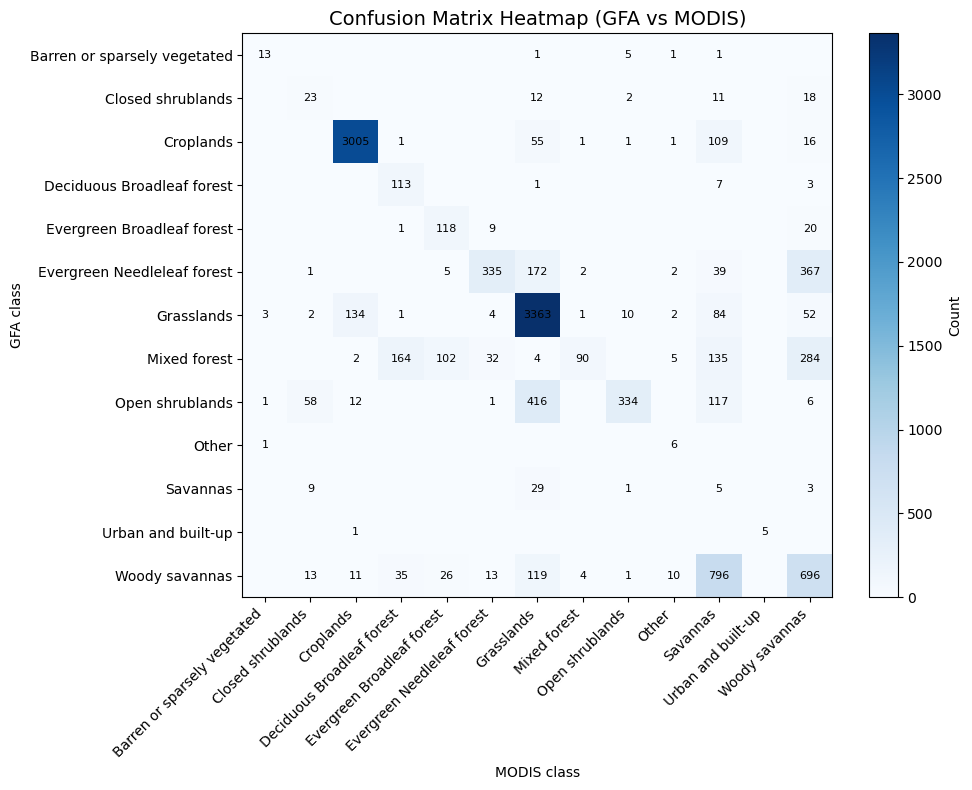

In [10]:
plc.plot_confusion_matrix(confusion)

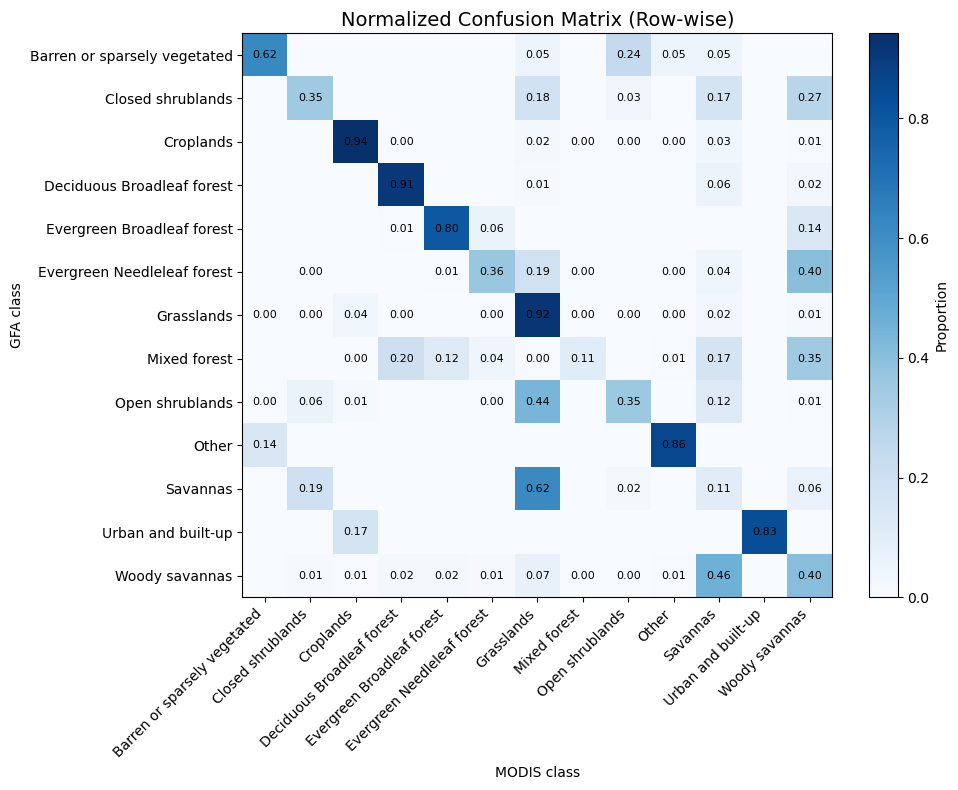

In [11]:
plc.plot_confusion_matrix(confusion, normalize=True)

In [12]:
rtab.print_overall_metrics(confusion)

=== Summary Statistics ===
Accuracy: 0.6943635429158814
Weighted F1: 0.7039366924365069
                              precision    recall  f1-score   support

Barren or sparsely vegetated       0.72      0.62      0.67        21
           Closed shrublands       0.22      0.35      0.27        66
                   Croplands       0.95      0.94      0.95      3189
  Deciduous Broadleaf forest       0.36      0.91      0.51       124
  Evergreen Broadleaf forest       0.47      0.80      0.59       148
 Evergreen Needleleaf forest       0.85      0.36      0.51       923
                  Grasslands       0.81      0.92      0.86      3656
                Mixed forest       0.92      0.11      0.20       818
             Open shrublands       0.94      0.35      0.51       945
                       Other       0.22      0.86      0.35         7
                    Savannas       0.00      0.11      0.01        47
          Urban and built-up       1.00      0.83      0.91         6
 

So, MODIS classifies fires by land cover type with relatively high accuracy. 

### Confirm that this prediction accuracy exists across the data's temporal range...

/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/src/wildfire_stats/plotting/landcover.py:349: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


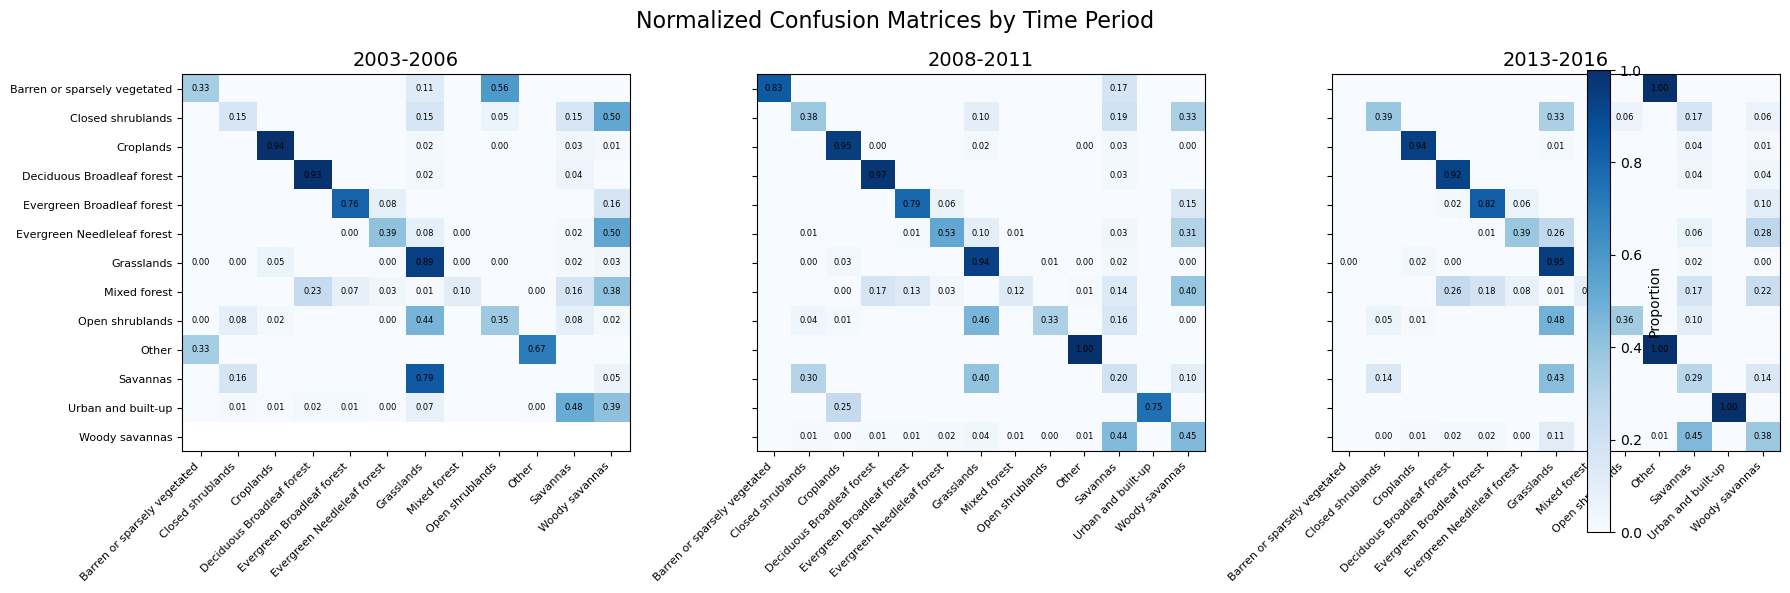


=== 2003-2006 ===
Accuracy: 0.684
Weighted Precision: 0.784
Weighted Recall: 0.684
Weighted F1: 0.695

=== 2008-2011 ===
Accuracy: 0.716
Weighted Precision: 0.822
Weighted Recall: 0.716
Weighted F1: 0.727

=== 2013-2016 ===
Accuracy: 0.717
Weighted Precision: 0.823
Weighted Recall: 0.717
Weighted F1: 0.724


In [13]:
periods = {
    "2003-2006": (2003, 2006),
    "2008-2011": (2008, 2011),
    "2013-2016": (2013, 2016)
}

metrics = plc.plot_confusion_by_period(gfa_classified, periods)
rtab.print_period_metrics(metrics)

Similar performance across temporal range!

# Run for a number of fire sizes

Only run if you want to loop over a number of different minimum fire sizes -- this will take a while

In [14]:
import pandas as pd

from wildfire_stats import config as cfg
from wildfire_stats.data import classification as dcls
from wildfire_stats.data import io as dio
from wildfire_stats.data import rasters as drast
from wildfire_stats.plotting import landcover as plc
from wildfire_stats.reporting import tables as rtab

P = cfg.load_paths()
A = cfg.load_assumptions()  # A["min_fire"] == MIN_FIRE_SIZE

# three options - Lucas's default, Lucas's empirical, my empirical
min_fire_sizes = [4, 4.5, 6.25]

for MIN_FIRE_SIZE in min_fire_sizes:
    cfg.set_overrides(min_fire=MIN_FIRE_SIZE)  # every library default (xmin, amin_min, ...) follows this
    MF_TAG = dio.minfire_tag()  # filename tag, e.g. "minfire6p45"
    
    # MIN_FIRE_SIZE is set in the setup cell (6.45 km² baseline; 4 km² = previous iteration)
    gfa_classified = results_df[results_df["area_km2"] >= MIN_FIRE_SIZE].copy()

    print(f"Fires >= {MIN_FIRE_SIZE} km²: {len(gfa_classified)}")

    gfa_classified = dcls.merge_classes(gfa_classified, ["modis_class", "gfa_class"])

    dio.save_vector(gfa_classified, P.logged_output / f"gfa_2003_2016_usa_classified_timevarying_{MF_TAG}.shp")

Fires >= 4 km²: 19851
Saved GeoDataFrame to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/logged_output/gfa_2003_2016_usa_classified_timevarying_minfire4.shp
Fires >= 4.5 km²: 17888


/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/src/wildfire_stats/data/io.py:253: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf.to_file(path)
/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/.env/lib/python3.10/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'modis_class' to 'modis_clas'
  ogr_write(
/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/src/wildfire_stats/data/io.py:253: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf.to_file(path)


Saved GeoDataFrame to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/logged_output/gfa_2003_2016_usa_classified_timevarying_minfire4p5.shp
Fires >= 6.25 km²: 12129
Saved GeoDataFrame to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/logged_output/gfa_2003_2016_usa_classified_timevarying_minfire6p25.shp


/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/.env/lib/python3.10/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'modis_class' to 'modis_clas'
  ogr_write(
/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/src/wildfire_stats/data/io.py:253: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf.to_file(path)
/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/.env/lib/python3.10/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'modis_class' to 'modis_clas'
  ogr_write(
